# ACP conjunto de almacenamiento y ambiente: escenario de distancia 5–20 cm

## Supuesto del caso

> “cuando el embalse esté lo más bajito quiero que lo ponderes a 20 centímetros y cuando esté lo más alto a 5 centímetros”

Definición literal de la escala de simulación adoptada para este caso. Construimos una **distancia simulada**, no una medición del HC-SR04: el volumen máximo observado en agosto de 2024 corresponde a 5 cm y el mínimo observado a 20 cm. Los extremos son relativos al periodo; no representan un embalse físicamente lleno o seco.

El objetivo es obtener la combinación lineal PC1 y expresar matemáticamente su reparto entre una variable hídrica y cuatro ambientales. El resultado es un **índice descriptivo exploratorio**. No se estima la eficacia de una alarma ni un porcentaje causal de evaporación. La escala se declara antes del análisis y no se ajusta para obtener 80/20.

El código está desarrollado en celdas secuenciales, sin módulos propios. Se incluyen las fuentes originales, sus URL y SHA-256, los datos derivados y las salidas. No se necesita acceso a archivos fuera de esta carpeta para reproducir el estudio.

## 1. Pregunta y alcance

**Pregunta:** con el volumen histórico transformado a una distancia 5–20 cm, ¿qué coeficientes obtiene un ACP conjunto y cómo se puede escribir PC1 como dos bloques: nivel simulado y ambiente?

Utilizamos Neusa porque dispone de volumen CAR y una serie NASA para el punto correspondiente. Los cuatro embalses de CAR se reconstruyen y conservan, pero no se replica el clima de Neusa sobre otros embalses. La serie NASA completa tiene 1.096 días; el ACP conjunto utiliza todas las **31 fechas coincidentes** de agosto de 2024. Añadir fechas sin volumen supondría inventar esa variable.

| Requisito académico | Evidencia del estudio | Validación adicional |
|---|---|---|
| Justificación de la lógica de fusión y criterios de diseño | Fórmula de distancia, ACP, signos y descomposición en bloques | Evento objetivo y ensayos del prototipo |
| Configuración experimental, resultados y análisis | Fuentes, unidades, controles, parámetros, tablas y gráficas | Correspondencia entre sensores reales y datos históricos |
| Comunicación técnica y referencias | Fórmulas explicadas, fuentes enlazadas y referencias numeradas | Sustentación oral y documentación completa en Wiki |
| Validación de la solución IoT | Comprobaciones numéricas y de reproducción de este análisis | Sensores, ISR, alarma, LCD, WLAN y tablero embebido |

El alcance se contrasta con el enunciado del segundo corte y la rúbrica `Rubricas_Entrega-CHx_IoT_20262 del 2do corte.xlsx`: diseño, validación, comunicación oral/escrita, apropiación y contribuciones del equipo. Este anexo no acredita por sí solo los restantes requisitos de Wiki, video, actas, prototipo y declaración de IA.

In [1]:
from pathlib import Path
import hashlib, json, re, shutil, ssl, subprocess, tempfile, os
from urllib.request import Request, urlopen
from datetime import datetime, timezone
import importlib.metadata

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "fusion_acp_mpl"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display, Markdown

BASE = Path.cwd().resolve()
if not (BASE / "datos/fuentes.json").is_file():
    raise FileNotFoundError("Ejecutar desde la carpeta que contiene este notebook y datos/.")
RESULTADOS = BASE / "resultados"
RESULTADOS.mkdir(exist_ok=True)
fuentes = json.loads((BASE / "datos/fuentes.json").read_text(encoding="utf-8"))
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 40)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
versiones = {p: importlib.metadata.version(p) for p in
             ["numpy", "pandas", "scikit-learn", "matplotlib", "jupyterlab", "ipykernel"]}
display(pd.Series(versiones, name="version"))
assert shutil.which("pdftotext"), "La reconstrucción de CAR requiere pdftotext (Poppler)."

numpy            2.4.6
pandas           3.0.6
scikit-learn     1.9.1
matplotlib      3.11.2
jupyterlab       4.6.4
ipykernel        7.4.0
Name: version, dtype: str

## 2. Fuentes y descarga

**CAR [1]:** 31 boletines PDF de agosto de 2024, cuatro embalses por boletín. Se conservan el volumen, la capacidad útil, el almacenamiento publicado, la descarga y la tendencia. Las unidades de volumen son millones de m³. Cada PDF tiene URL individual y hash en `datos/fuentes.json`.

**NASA POWER [2]:** consulta diaria 2023–2025 para latitud 5,133333333 y longitud −73,96666667. El JSON incluye temperatura, humedad relativa, presión, radiación, precipitación y viento. Son datos de grilla; no son observaciones del ESP32 ni de una estación IDEAM. La consulta usa comunidad `AG`, radiación en MJ/m²/día y tiempo solar local `LST`.

**IDEAM:** sus series del estudio previo no se integran en esta matriz. La humedad histórica examinada tiene descripción de humedad del suelo, mientras este análisis necesita humedad relativa del aire. No se corrige esa discrepancia por suposición ni se mezclan estaciones.

La siguiente tabla proporciona enlaces descargables a todas las fuentes utilizadas. La reproducción normal lee las copias incluidas. La opción posterior permite volver a obtener los originales de sus entidades. Se registra su SHA-256; en NASA también se compara el JSON completo excluyendo únicamente `times`, que registra la latencia de respuesta y cambia entre consultas. Los datos, parámetros, geometría y demás metadatos deben coincidir. Los PDF CAR deben coincidir íntegramente.

In [2]:
integridad = []
for fuente in fuentes:
    archivo = BASE / fuente["archivo"]
    actual = hashlib.sha256(archivo.read_bytes()).hexdigest()
    assert actual == fuente["sha256"], "Fuente modificada: " + fuente["archivo"]
    integridad.append({"archivo": fuente["archivo"], "sha256": actual, "integro": True})
pd.DataFrame(integridad).to_csv(RESULTADOS / "integridad_fuentes.csv", index=False)
originales = [f for f in fuentes if f["url"]]
print(f"Integridad verificada: {len(originales)} originales y {len(fuentes)-len(originales)} tablas derivadas.")
print("Consulta NASA completa:")
print(next(f["url"] for f in originales if f["entidad"] == "NASA POWER"))
filas_enlaces = ["| Entidad / fecha | Fuente |", "|---|---|"]
for f in originales:
    etiqueta = f["entidad"] + " " + f.get("fecha", "2023–2025")
    filas_enlaces.append(f"| {etiqueta} | [Descargar original]({f['url']}) |")
display(Markdown("\n".join(filas_enlaces)))

Integridad verificada: 32 originales y 2 tablas derivadas.
Consulta NASA completa:
https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M%2CT2M_MAX%2CT2M_MIN%2CRH2M%2CPS%2CALLSKY_SFC_SW_DWN%2CPRECTOTCORR%2CWS2M&community=AG&longitude=-73.96666667&latitude=5.133333333&start=20230101&end=20251231&format=JSON&time-standard=LST


| Entidad / fecha | Fuente |
|---|---|
| NASA POWER 2023–2025 | [Descargar original](https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M%2CT2M_MAX%2CT2M_MIN%2CRH2M%2CPS%2CALLSKY_SFC_SW_DWN%2CPRECTOTCORR%2CWS2M&community=AG&longitude=-73.96666667&latitude=5.133333333&start=20230101&end=20251231&format=JSON&time-standard=LST) |
| CAR 2024-08-01 | [Descargar original](https://car1.car.gov.co/uploads/files/66abce5249a07.pdf) |
| CAR 2024-08-02 | [Descargar original](https://car1.car.gov.co/uploads/files/66ad147187195.pdf) |
| CAR 2024-08-03 | [Descargar original](https://car1.car.gov.co/uploads/files/66aea2bfae41d.pdf) |
| CAR 2024-08-04 | [Descargar original](https://car1.car.gov.co/uploads/files/66afca1e14a0e.pdf) |
| CAR 2024-08-05 | [Descargar original](https://car1.car.gov.co/uploads/files/66b10f6f028b1.pdf) |
| CAR 2024-08-06 | [Descargar original](https://car1.car.gov.co/uploads/files/66b2580ec4e40.pdf) |
| CAR 2024-08-07 | [Descargar original](https://car1.car.gov.co/uploads/files/66b3b3545cdba.pdf) |
| CAR 2024-08-08 | [Descargar original](https://car1.car.gov.co/uploads/files/66b506ba9e3a5.pdf) |
| CAR 2024-08-09 | [Descargar original](https://car1.car.gov.co/uploads/files/66b657079ded1.pdf) |
| CAR 2024-08-10 | [Descargar original](https://car1.car.gov.co/uploads/files/66b7a813aa75b.pdf) |
| CAR 2024-08-11 | [Descargar original](https://car1.car.gov.co/uploads/files/66b8faa550436.pdf) |
| CAR 2024-08-12 | [Descargar original](https://car1.car.gov.co/uploads/files/66ba412a4d05c.pdf) |
| CAR 2024-08-13 | [Descargar original](https://car1.car.gov.co/uploads/files/66bb9db92c540.pdf) |
| CAR 2024-08-14 | [Descargar original](https://car1.car.gov.co/uploads/files/66bcedac8cd5f.pdf) |
| CAR 2024-08-15 | [Descargar original](https://car1.car.gov.co/uploads/files/66be39b075a65.pdf) |
| CAR 2024-08-16 | [Descargar original](https://car1.car.gov.co/uploads/files/66bf8b44ce63c.pdf) |
| CAR 2024-08-17 | [Descargar original](https://car1.car.gov.co/uploads/files/66c0dafc0bbe7.pdf) |
| CAR 2024-08-18 | [Descargar original](https://car1.car.gov.co/uploads/files/66c22cdec7798.pdf) |
| CAR 2024-08-19 | [Descargar original](https://car1.car.gov.co/uploads/files/66c388789d3c2.pdf) |
| CAR 2024-08-20 | [Descargar original](https://car1.car.gov.co/uploads/files/66c4d8b89c0d5.pdf) |
| CAR 2024-08-21 | [Descargar original](https://car1.car.gov.co/uploads/files/66c61f43cd75b.pdf) |
| CAR 2024-08-22 | [Descargar original](https://car1.car.gov.co/uploads/files/66c770cb60015.pdf) |
| CAR 2024-08-23 | [Descargar original](https://car1.car.gov.co/uploads/files/66c8c19c77619.pdf) |
| CAR 2024-08-24 | [Descargar original](https://car1.car.gov.co/uploads/files/66ca1599ae37d.pdf) |
| CAR 2024-08-25 | [Descargar original](https://car1.car.gov.co/uploads/files/66cb6dfe2ce46.pdf) |
| CAR 2024-08-26 | [Descargar original](https://car1.car.gov.co/uploads/files/66ccd04e59eb2.pdf) |
| CAR 2024-08-27 | [Descargar original](https://car1.car.gov.co/uploads/files/66ce2699ab1f7.pdf) |
| CAR 2024-08-28 | [Descargar original](https://car1.car.gov.co/uploads/files/66cf5730cea57.pdf) |
| CAR 2024-08-29 | [Descargar original](https://car1.car.gov.co/uploads/files/66d0b01224a93.pdf) |
| CAR 2024-08-30 | [Descargar original](https://car1.car.gov.co/uploads/files/66d1fbfd1b56a.pdf) |
| CAR 2024-08-31 | [Descargar original](https://car1.car.gov.co/uploads/files/66d363cb8fb11.pdf) |

In [3]:
# False: reproducción local. True: nueva descarga de las 32 fuentes originales.
DESCARGAR_DE_NUEVO = False
ORIGINALES = BASE / "datos/originales"
if DESCARGAR_DE_NUEVO:
    ORIGINALES = BASE / "descargas"
    contexto_tls = ssl.create_default_context()
    # Intermedios publicados por DigiCert: completan la cadena CAR sin desactivar TLS.
    for certificado in (BASE / "datos/certificados").glob("*.crt"):
        contexto_tls.load_verify_locations(cadata=ssl.DER_cert_to_PEM_cert(certificado.read_bytes()))
    auditoria_descarga = []
    for f in originales:
        relativo = Path(f["archivo"]).relative_to("datos/originales")
        destino = ORIGINALES / relativo
        destino.parent.mkdir(parents=True, exist_ok=True)
        nueva = not destino.exists()
        if nueva:
            request = Request(f["url"], headers={"User-Agent": "Analisis-IoT-Academico/1.0"})
            with urlopen(request, context=contexto_tls, timeout=60) as respuesta:
                contenido = respuesta.read()
            with destino.open("xb") as salida:
                salida.write(contenido)
        actual = hashlib.sha256(destino.read_bytes()).hexdigest()
        contenido_verificado = actual == f["sha256"]
        if f["entidad"] == "NASA POWER":
            esperado = json.loads((BASE / f["archivo"]).read_text(encoding="utf-8"))
            recibido = json.loads(destino.read_text(encoding="utf-8"))
            # NASA actualiza times (latencia de respuesta); no contiene mediciones.
            esperado.pop("times", None)
            recibido.pop("times", None)
            contenido_verificado = esperado == recibido
        auditoria_descarga.append({"url": f["url"], "archivo": str(relativo),
                                   "consulta_utc": datetime.now(timezone.utc).isoformat(),
                                   "descargado_en_esta_ejecucion": nueva, "sha256": actual,
                                   "coincide_con_version_preservada": actual == f["sha256"],
                                   "contenido_verificado": contenido_verificado})
        pd.DataFrame(auditoria_descarga).to_csv(RESULTADOS / "auditoria_descarga.csv", index=False)
        assert contenido_verificado, "Cambió el contenido de la fuente; revisar la versión antes de continuar."
    print("Originales descargados o recuperados de la caché y verificados.")
else:
    print("Se utilizan originales incluidos. No se realizó una nueva descarga.")

Se utilizan originales incluidos. No se realizó una nueva descarga.


## 3. Reconstrucción de NASA desde el JSON

Se reconstruyen las ocho series originales. El valor de ausencia `fill_value` pasa a `NaN`; la presión se expresa además en hPa mediante `PS × 10`. No se imputan ni recortan datos. Se comparan todas las fechas y columnas numéricas con el CSV preservado.

`LST` identifica el periodo diario solar local [2]. El volumen CAR es una observación publicada, por lo que la unión por fecha se utiliza como aproximación exploratoria, no como una sincronización instrumental exacta. La altitud de la geometría NASA pertenece al producto de grilla, no al sensor.

In [4]:
raw = json.loads((ORIGINALES / "nasa_power_neusa_2023_2025.json").read_text(encoding="utf-8"))
parametros = {"T2M": "temperatura_media_C", "T2M_MAX": "temperatura_max_C",
              "T2M_MIN": "temperatura_min_C", "RH2M": "humedad_relativa_pct",
              "PS": "presion_kPa", "ALLSKY_SFC_SW_DWN": "radiacion_MJ_m2_dia",
              "PRECTOTCORR": "precipitacion_mm_dia", "WS2M": "viento_2m_m_s"}
series = raw["properties"]["parameter"]
nasa = pd.DataFrame({nombre: pd.Series(series[codigo], dtype=float)
                     for codigo, nombre in parametros.items()})
nasa.index = pd.to_datetime(nasa.index, format="%Y%m%d")
nasa.index.name = "fecha"
nasa = nasa.sort_index().replace(raw["header"]["fill_value"], np.nan)
nasa["presion_hPa"] = nasa.presion_kPa * 10
assert nasa.index.equals(pd.date_range("2023-01-01", "2025-12-31", name="fecha"))
assert raw["header"]["time_standard"] == "LST"
assert raw["parameters"]["PS"]["units"] == "kPa"
assert raw["parameters"]["ALLSKY_SFC_SW_DWN"]["units"] == "MJ/m^2/day"
preservado = pd.read_csv(BASE / "datos/nasa_power_neusa_diario_2023_2025.csv",
                        parse_dates=["fecha"]).set_index("fecha").sort_index()
pd.testing.assert_index_equal(nasa.index, preservado.index)
np.testing.assert_allclose(nasa, preservado[nasa.columns], equal_nan=True)
print("Días reconstruidos:", len(nasa))
print("Geometría NASA:", raw["geometry"])
display(pd.DataFrame(raw["parameters"]).T)
nasa.to_csv(RESULTADOS / "nasa_reconstruido.csv")

Días reconstruidos: 1096
Geometría NASA: {'type': 'Point', 'coordinates': [-73.967, 5.133, 2476.01]}


,units,longname
T2M,C,Temperature at 2 Meters
T2M_MAX,C,Temperature at 2 Meters Maximum
T2M_MIN,C,Temperature at 2 Meters Minimum
RH2M,%,Relative Humidity at 2 Meters
PS,kPa,Surface Pressure
ALLSKY_SFC_SW_DWN,MJ/m^2/day,All Sky Surface Shortwave Downward Irradiance
PRECTOTCORR,mm/day,Precipitation Corrected
WS2M,m/s,Wind Speed at 2 Meters


## 4. Reconstrucción de CAR desde los PDF

Se extrae texto con `pdftotext -layout`, se identifica la fecha del boletín y se leen las cuatro filas de embalses. Los decimales se convierten a números y se preserva el almacenamiento publicado, sin sustituirlo por un porcentaje recalculado. La tabla resultante debe coincidir con el CSV existente.

In [5]:
numero = r"(\d+(?:[.,]\d+)?)"
patron = re.compile(r"^\s*(Neusa|Sisga|Tominé|El Hato)\s+" +
                    r"\s+".join([numero, numero, numero + r"%", numero, numero]) +
                    r"\s+(ASCENDENTE|DESCENDENTE|ESTABLE)\s*$", re.MULTILINE)
campos = ["embalse", "capacidad_util_Mm3", "volumen_Mm3", "almacenamiento_pct",
          "descarga_m3_s", "capacidad_regulacion_Mm3", "tendencia_publicada"]
registros = []
for fuente in originales:
    if fuente["entidad"] != "CAR":
        continue
    pdf = ORIGINALES / "car_pdf" / Path(fuente["archivo"]).name
    texto = subprocess.run(["pdftotext", "-layout", str(pdf), "-"], stdin=subprocess.DEVNULL,
                           capture_output=True, text=True, check=True, timeout=30).stdout
    fecha_pdf = re.search(r"(\d{1,2})\s+Agosto\s+2024", texto)
    assert fecha_pdf and int(fecha_pdf.group(1)) == int(fuente["fecha"][-2:])
    coincidencias = list(patron.finditer(texto))
    assert len(coincidencias) == 4, "No se recuperaron los cuatro embalses."
    for coincidencia in coincidencias:
        fila = dict(zip(campos, coincidencia.groups()))
        for columna in campos[1:6]:
            fila[columna] = float(fila[columna].replace(",", "."))
        fila.update(fecha=fuente["fecha"], fuente_url=fuente["url"])
        registros.append(fila)
car = pd.DataFrame(registros).sort_values(["fecha", "embalse"]).reset_index(drop=True)
car_csv = pd.read_csv(BASE / "datos/car_embalses_agosto_2024.csv").sort_values(
    ["fecha", "embalse"]).reset_index(drop=True)
pd.testing.assert_frame_equal(car[car_csv.columns], car_csv, check_dtype=False)
assert len(car) == 124 and not car.duplicated(["fecha", "embalse"]).any()
car["fecha"] = pd.to_datetime(car.fecha)
display(car.groupby("embalse").agg(fechas=("fecha", "size"),
                                   volumen_min_Mm3=("volumen_Mm3", "min"),
                                   volumen_max_Mm3=("volumen_Mm3", "max")))
car.to_csv(RESULTADOS / "car_reconstruido.csv", index=False)

,fechas,volumen_min_Mm3,volumen_max_Mm3
embalse,,,
El Hato,31,10.327,10.523
Neusa,31,78.497,80.421
Sisga,31,63.134,64.743
Tominé,31,358.498,367.222


## 5. Unión de fuentes y construcción de la distancia simulada

Para un volumen `V` dentro del intervalo observado:

**d_sim(V) = 5 + 15 × (V_max − V) / (V_max − V_min).**

Así, el volumen mayor corresponde a 5 cm, el menor a 20 cm y el punto medio a 12,5 cm. La escala relativa de descenso es `N = (d_sim − 5) / 15`; va de 0 a 1 en este periodo. No es una probabilidad ni una medida de litros consumidos.

No se conoce una curva nivel–volumen ni la geometría de instalación que permita convertir este volumen en distancia física del sensor. Por eso todas las columnas derivadas llevan el nombre **simulada**. No se introducen simultáneamente volumen, almacenamiento y distancia en el ACP: describirían repetidamente la misma información hídrica.

,volumen_Mm3,almacenamiento_pct,distancia_simulada_cm
fecha,,,
2024-08-01,80.421,78.61,5.0
2024-08-31,78.497,76.73,20.0


El mínimo observado conserva **76.73 %** de almacenamiento publicado. En este escenario, **20 cm no significa que el embalse esté seco**.

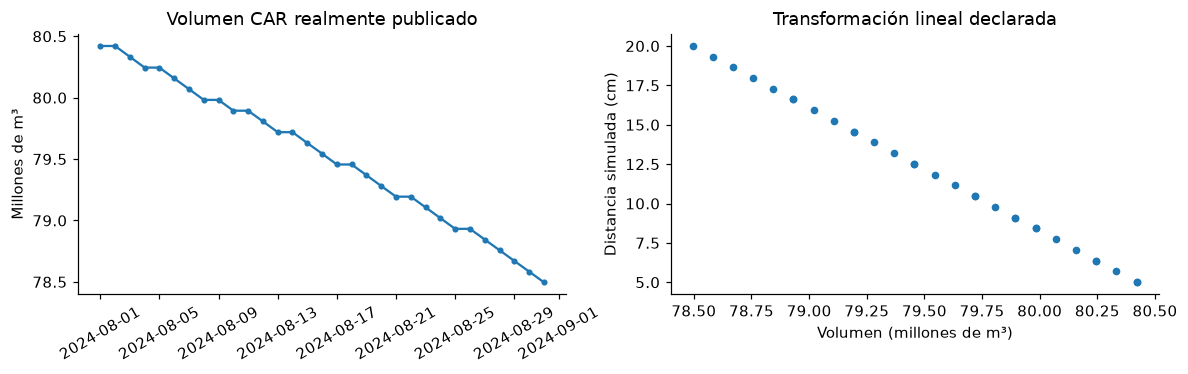

In [6]:
neusa = car.loc[car.embalse.eq("Neusa")].set_index("fecha").sort_index()
datos = neusa.join(nasa, how="inner", validate="one_to_one")
assert len(datos) == 31
V_min = float(datos.volumen_Mm3.min())
V_max = float(datos.volumen_Mm3.max())
D_min, D_max = 5.0, 20.0
assert V_max > V_min
# Simulación declarada del caso: no es una conversión física nivel-volumen.
datos["distancia_simulada_cm"] = D_min + (D_max-D_min)*(V_max-datos.volumen_Mm3)/(V_max-V_min)
datos["descenso_relativo_simulado"] = (datos.distancia_simulada_cm-D_min)/(D_max-D_min)
np.testing.assert_allclose(datos.distancia_simulada_cm.min(), D_min)
np.testing.assert_allclose(datos.distancia_simulada_cm.max(), D_max)
assert datos.distancia_simulada_cm.between(D_min, D_max).all()
assert np.corrcoef(datos.volumen_Mm3, datos.distancia_simulada_cm)[0,1] < -.999999
extremos = datos.loc[[datos.volumen_Mm3.idxmax(), datos.volumen_Mm3.idxmin()],
                    ["volumen_Mm3", "almacenamiento_pct", "distancia_simulada_cm"]]
display(extremos)
display(Markdown(f"El mínimo observado conserva **{datos.almacenamiento_pct.min():.2f} %** "
                 "de almacenamiento publicado. En este escenario, **20 cm no significa que el embalse esté seco**."))
datos.to_csv(RESULTADOS / "datos_neusa_con_distancia_simulada.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(datos.index, datos.volumen_Mm3, "o-", markersize=3)
axes[0].set(title="Volumen CAR realmente publicado", ylabel="Millones de m³")
axes[0].tick_params(axis="x", rotation=30)
axes[1].plot(datos.volumen_Mm3, datos.distancia_simulada_cm, "o", markersize=4)
axes[1].set(title="Transformación lineal declarada", xlabel="Volumen (millones de m³)",
            ylabel="Distancia simulada (cm)")
fig.tight_layout()
fig.savefig(RESULTADOS / "01_volumen_y_distancia.png")
plt.show()

## 6. Matriz del ACP, correlaciones y estandarización

La matriz utiliza cinco variables: distancia simulada, radiación, temperatura media, humedad relativa y presión. Las cuatro variables ambientales se seleccionan por su correspondencia conceptual con el índice del firmware, sin suponer equivalencia instrumental.

La luz relativa del LDR no equivale a radiación diaria en MJ/m²/día. La presión de grilla y la del BMP180 pueden diferir por altitud. El viento y la precipitación se preservan, pero no forman parte de este índice de cinco variables. Su exclusión delimita el modelo; no demuestra que carezcan de importancia para evaporación.

Calculamos `z = (x − media) / desviación`, con desviación poblacional (`ddof=0`) [3]. El ACP de scikit-learn centra, pero no estandariza automáticamente [4]. Así se evita que la unidad de medida determine por sí sola el resultado.

In [7]:
variables = ["distancia_simulada_cm", "radiacion_MJ_m2_dia", "temperatura_media_C",
             "humedad_relativa_pct", "presion_hPa"]
X = datos[variables]
assert not X.isna().any().any() and np.isfinite(X.to_numpy()).all()
assert (X.std(ddof=0) > 0).all()
display(X.describe().T)
correlaciones = X.corr()
display(correlaciones)
escalador = StandardScaler()
Z = escalador.fit_transform(X)
escala = pd.DataFrame({"media": escalador.mean_, "desviacion_ddof0": escalador.scale_}, index=variables)
np.testing.assert_allclose(Z.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(Z.std(axis=0), 1)
display(escala)
escala.to_csv(RESULTADOS / "medias_y_desviaciones.csv")
correlaciones.to_csv(RESULTADOS / "correlaciones.csv")

,count,mean,std,min,25%,50%,75%,max
distancia_simulada_cm,31.0,11.964322,4.504945,5.00,8.422557,11.837318,15.587318,20.00
radiacion_MJ_m2_dia,31.0,17.083548,2.980952,12.38,14.540000,16.630000,19.430000,24.27
temperatura_media_C,31.0,13.589355,0.648171,12.61,13.005000,13.640000,14.100000,14.84
humedad_relativa_pct,31.0,85.305161,2.513387,77.49,84.050000,86.380000,86.840000,88.43
presion_hPa,31.0,760.048387,0.623362,758.60,759.600000,760.300000,760.450000,761.10


,distancia_simulada_cm,radiacion_MJ_m2_dia,temperatura_media_C,humedad_relativa_pct,presion_hPa
distancia_simulada_cm,1.000000,-0.079930,-0.129660,-0.475827,0.323909
radiacion_MJ_m2_dia,-0.079930,1.000000,-0.112377,-0.445537,-0.024330
temperatura_media_C,-0.129660,-0.112377,1.000000,0.437639,-0.722116
humedad_relativa_pct,-0.475827,-0.445537,0.437639,1.000000,-0.304085
presion_hPa,0.323909,-0.024330,-0.722116,-0.304085,1.000000


,media,desviacion_ddof0
distancia_simulada_cm,11.964322,4.431689
radiacion_MJ_m2_dia,17.083548,2.932478
temperatura_media_C,13.589355,0.637631
humedad_relativa_pct,85.305161,2.472516
presion_hPa,760.048387,0.613226


## 7. ACP conjunto

Ajustamos las cinco componentes mediante SVD completo [4]. Orientamos PC1 de manera que su coeficiente de distancia sea positivo. Cambiar todos sus signos no modifica el eje ni su varianza explicada.

Se presentan por separado:

- **Coeficientes:** números que multiplican las variables estandarizadas para calcular PC1.
- **Cargas:** correlaciones variable–componente.
- **Contribuciones cuadráticas:** `100 × coeficiente²` dentro de cada componente; suman 100 %, pero no representan riesgo.
- **Varianza explicada:** fracción de variación de la matriz resumida por cada componente; no es exactitud predictiva.

,PC1,PC2,PC3,PC4,PC5
distancia_simulada_cm,0.370938,-0.140318,0.784726,0.278765,-0.386279
radiacion_MJ_m2_dia,0.196775,0.797595,-0.218240,0.491555,-0.189385
temperatura_media_C,-0.532626,0.192686,0.460643,0.334638,0.595825
humedad_relativa_pct,-0.518748,-0.390273,-0.247104,0.554737,-0.458033
presion_hPa,0.520476,-0.393335,-0.251645,0.510830,0.500120


,PC1,PC2,PC3,PC4,PC5
distancia_simulada_cm,0.558098,-0.154790,0.781612,0.164938,-0.162616
radiacion_MJ_m2_dia,0.296060,0.879859,-0.217374,0.290841,-0.079727
temperatura_media_C,-0.801366,0.212560,0.458815,0.197997,0.250831
humedad_relativa_pct,-0.780486,-0.430525,-0.246124,0.328224,-0.192823
presion_hPa,0.783086,-0.433904,-0.250646,0.302246,0.210541


,componente,autovalor,varianza_pct,acumulada_pct
0,PC1,2.339152,45.273919,45.273919
1,PC2,1.257482,24.338367,69.612286
2,PC3,1.025150,19.841622,89.453908
3,PC4,0.361749,7.001586,96.455494
4,PC5,0.183133,3.544506,100.000000


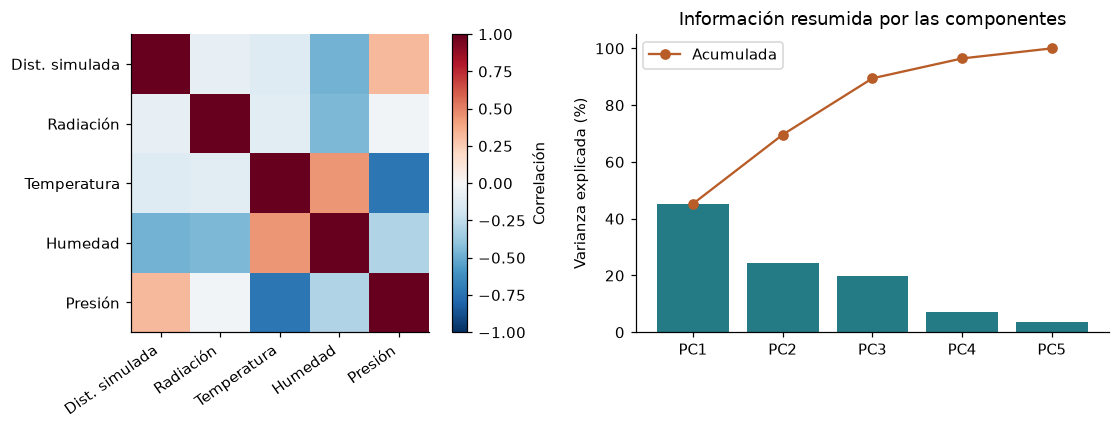

In [8]:
pca = PCA(svd_solver="full")
scores = pca.fit_transform(Z)
if pca.components_[0,0] < 0:
    pca.components_[0] *= -1
    scores[:,0] *= -1
nombres_pc = [f"PC{i+1}" for i in range(len(variables))]
coeficientes = pd.DataFrame(pca.components_.T, index=variables, columns=nombres_pc)
cargas = pd.DataFrame(np.corrcoef(Z.T, scores.T)[:5,5:], index=variables, columns=nombres_pc)
contribuciones = 100*coeficientes.pow(2)
varianza = pd.DataFrame({"componente": nombres_pc, "autovalor": pca.explained_variance_,
                         "varianza_pct": 100*pca.explained_variance_ratio_,
                         "acumulada_pct": 100*np.cumsum(pca.explained_variance_ratio_)})
np.testing.assert_allclose(pca.transform(Z), scores, atol=1e-12)
np.testing.assert_allclose(contribuciones.sum(), 100)
display(coeficientes)
display(cargas)
display(varianza)
for nombre, tabla in [("coeficientes",coeficientes),("cargas",cargas),
                       ("contribuciones_cuadraticas",contribuciones),("varianza",varianza)]:
    tabla.to_csv(RESULTADOS / f"acp_{nombre}.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(correlaciones, vmin=-1, vmax=1, cmap="RdBu_r")
etiquetas = ["Dist. simulada", "Radiación", "Temperatura", "Humedad", "Presión"]
axes[0].set_xticks(range(5), etiquetas, rotation=35, ha="right")
axes[0].set_yticks(range(5), etiquetas)
fig.colorbar(im, ax=axes[0], label="Correlación")
axes[1].bar(varianza.componente, varianza.varianza_pct, color="#247b86")
axes[1].plot(varianza.componente, varianza.acumulada_pct, "o-", color="#b85c28", label="Acumulada")
axes[1].set(title="Información resumida por las componentes", ylabel="Varianza explicada (%)", ylim=(0,105))
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTADOS / "02_correlaciones_y_varianza.png")
plt.show()

## 8. De los coeficientes a la expresión X·nivel + Y·ambiente

Para presentar PC1 en dos bloques sin alterar sus signos definimos una **normalización L1 de presentación**, adicional al ACP:

`L = Σ|aᵢ|`, `bᵢ = aᵢ/L`, `S = PC1/L`.

Después separamos:

`X = |b_distancia|`, `Y = Σ_ambiente |bᵢ|`, `A = Σ_ambiente (bᵢ/Y)·zᵢ`.

Como orientamos el coeficiente de distancia hacia el signo positivo, resulta exactamente:

**S = X·z_distancia + Y·A**, con **X + Y = 1**.

X e Y son participaciones absolutas de los coeficientes en esta representación de PC1. La normalización L1 es una convención explícita para presentar la combinación en bloques; no es una ponderación de alarma aprendida por el ACP. Las contribuciones cuadráticas de la sección anterior responden a otra definición y no deben intercambiarse con X e Y.

El reparto agrupa una variable hídrica frente a cuatro ambientales: depende de la lista de variables y de la normalización elegida. No constituye una comparación experimental de importancia entre ambos fenómenos.

El bloque A conserva coeficientes negativos. No se toman valores absolutos para sumarlos como riesgos positivos, porque eso produciría otro índice distinto. Tampoco se multiplica por estos números el índice ambiental previo del Arduino: aquí A tiene una fórmula nueva sobre z-scores.

In [9]:
a = coeficientes.PC1.to_numpy()
L = np.abs(a).sum()
b = a/L
peso_nivel = float(abs(b[0]))
peso_ambiente = float(np.abs(b[1:]).sum())
coef_ambiente = b[1:]/peso_ambiente
Z_centrado = Z-pca.mean_
A = Z_centrado[:,1:] @ coef_ambiente
S = peso_nivel*Z_centrado[:,0] + peso_ambiente*A
np.testing.assert_allclose(peso_nivel+peso_ambiente, 1)
np.testing.assert_allclose(S, scores[:,0]/L, atol=1e-12)
reparto = pd.DataFrame({"bloque": ["Distancia simulada", "Ambiente"],
                        "participacion_absoluta_L1_pct": [100*peso_nivel,100*peso_ambiente]})
formula = pd.DataFrame({"variable": variables, "coeficiente_PC1": a,
                        "coeficiente_S_con_signo": b,
                        "participacion_absoluta_L1_pct": 100*np.abs(b),
                        "contribucion_cuadratica_PC1_pct": 100*a*a})
display(reparto)
display(formula)
display(pd.Series(coef_ambiente, index=variables[1:], name="coeficiente_del_bloque_A"))
print("PC1 =", " ".join(f"{v:+.6f}·z({nombre})" for nombre,v in zip(variables,a)))
print(f"S = {peso_nivel:.6f}·z(distancia_simulada) + {peso_ambiente:.6f}·A")
print("A =", " ".join(f"{v:+.6f}·z({nombre})" for nombre,v in zip(variables[1:],coef_ambiente)))
reparto.to_csv(RESULTADOS / "reparto_nivel_ambiente_L1.csv", index=False)
formula.to_csv(RESULTADOS / "formula_PC1_y_S.csv", index=False)
display(Markdown(f"**Resultado descriptivo:** {100*peso_nivel:.2f} % distancia simulada / "
                 f"{100*peso_ambiente:.2f} % ambiente; PC1 explica **{varianza.varianza_pct.iloc[0]:.2f} %** "
                 "de la variación. Este resultado no es un 80/20 validado para una alarma."))

,bloque,participacion_absoluta_L1_pct
0,Distancia simulada,17.337104
1,Ambiente,82.662896


,variable,coeficiente_PC1,coeficiente_S_con_signo,participacion_absoluta_L1_pct,contribucion_cuadratica_PC1_pct
0,distancia_simulada_cm,0.370938,0.173371,17.337104,13.759515
1,radiacion_MJ_m2_dia,0.196775,0.091970,9.196983,3.872048
2,temperatura_media_C,-0.532626,-0.248941,24.894131,28.368995
3,humedad_relativa_pct,-0.518748,-0.242455,24.245509,26.909933
4,presion_hPa,0.520476,0.243263,24.326272,27.089509


radiacion_MJ_m2_dia     0.111259
temperatura_media_C    -0.301152
humedad_relativa_pct   -0.293306
presion_hPa             0.294283
Name: coeficiente_del_bloque_A, dtype: float64

PC1 = +0.370938·z(distancia_simulada_cm) +0.196775·z(radiacion_MJ_m2_dia) -0.532626·z(temperatura_media_C) -0.518748·z(humedad_relativa_pct) +0.520476·z(presion_hPa)
S = 0.173371·z(distancia_simulada) + 0.826629·A
A = +0.111259·z(radiacion_MJ_m2_dia) -0.301152·z(temperatura_media_C) -0.293306·z(humedad_relativa_pct) +0.294283·z(presion_hPa)


**Resultado descriptivo:** 17.34 % distancia simulada / 82.66 % ambiente; PC1 explica **45.27 %** de la variación. Este resultado no es un 80/20 validado para una alarma.

## 9. Escala final de visualización y significado de los signos

Para visualizar S entre 0 y 100 dentro de la muestra usamos `I = 100 × (S − S_min)/(S_max − S_min)`. Esta transformación se aplica al índice completo. No se normaliza cada bloque por separado manteniendo X e Y, porque eso rompería la equivalencia anterior.

El cero y el cien son extremos del patrón observado; **no significan seguridad absoluta o desabastecimiento seguro**. No se selecciona un umbral de alarma con esta escala. Fuera de la muestra, la fórmula puede producir valores inferiores a 0 o superiores a 100; se conservan para identificar extrapolación en vez de ocultarla mediante recorte.

Un coeficiente negativo de temperatura resume una asociación de este mes y lugar. No demuestra que aumentar la temperatura reduzca evaporación. La combinación incluye estructura estacional, operación del embalse y otras variables omitidas. PC1 conserva menos de la mitad de la variación, por lo que su elección como único indicador implica pérdida de información.

,distancia_simulada_cm,nivel_relativo_simulado_pct,PC1,A,S,indice_descriptivo_pct
fecha,,,,,,
2024-08-01,5.000000,0.000000,0.614437,0.677001,0.287179,54.050052
2024-08-02,5.000000,0.000000,0.591619,0.664099,0.276514,53.655279
2024-08-03,5.686071,4.573805,-2.092968,-0.886265,-0.978222,7.210621
2024-08-04,6.372141,9.147609,-1.524044,-0.597058,-0.712316,17.053287
2024-08-05,6.372141,9.147609,-1.852893,-0.782993,-0.866015,11.364029


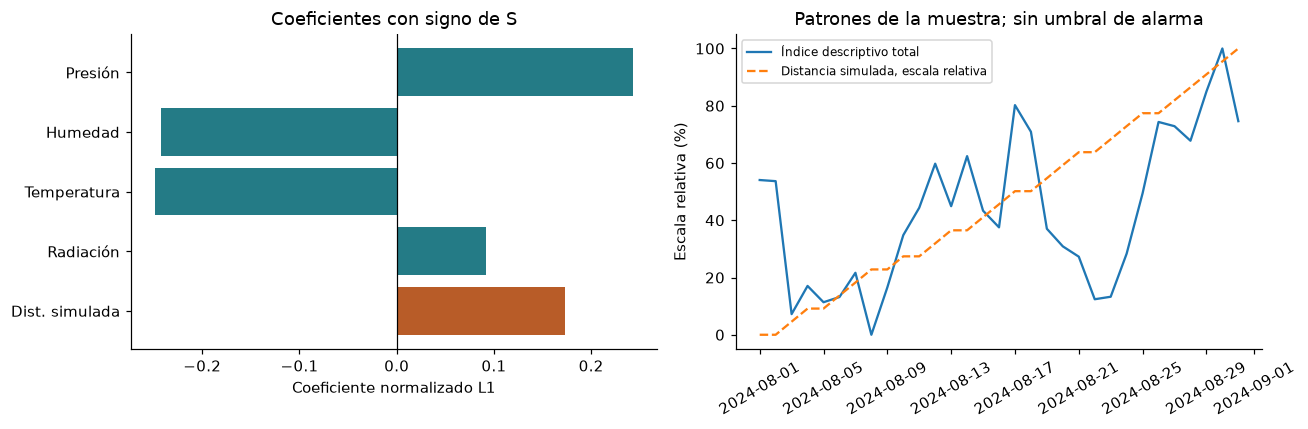

In [10]:
S_min, S_max = float(S.min()), float(S.max())
assert S_max > S_min
indice = 100*(S-S_min)/(S_max-S_min)
np.testing.assert_allclose([indice.min(),indice.max()], [0,100], atol=1e-10)
serie = pd.DataFrame({"distancia_simulada_cm": datos.distancia_simulada_cm,
                      "nivel_relativo_simulado_pct": 100*datos.descenso_relativo_simulado,
                      "PC1": scores[:,0], "A": A, "S": S,
                      "indice_descriptivo_pct": indice}, index=datos.index)
display(serie.head())
serie.to_csv(RESULTADOS / "serie_indice_descriptivo.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(etiquetas, b, color=["#b85c28"]+["#247b86"]*4)
axes[0].axvline(0, color="black", linewidth=.8)
axes[0].set(title="Coeficientes con signo de S", xlabel="Coeficiente normalizado L1")
axes[1].plot(serie.index, serie.indice_descriptivo_pct, label="Índice descriptivo total")
axes[1].plot(serie.index, serie.nivel_relativo_simulado_pct, label="Distancia simulada, escala relativa", linestyle="--")
axes[1].set(title="Patrones de la muestra; sin umbral de alarma", ylabel="Escala relativa (%)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTADOS / "03_coeficientes_y_serie.png")
plt.show()

## 10. Sensibilidad: qué depende de los supuestos y de la muestra

Cambiar 5–20 cm por otro intervalo lineal creciente de distancia **no cambia su z-score**, porque la estandarización elimina origen y escala. Tampoco agrega información: la distancia sigue siendo una transformación exacta e inversa del volumen.

Por tanto, escoger centímetros distintos no permite aumentar legítimamente su peso en un ACP estandarizado. Para priorizar nivel por política de ingeniería se necesita declarar una decisión separada, o evaluar una función de alarma con un objetivo y evidencia independientes.

Comparamos el mes completo con dos quincenas, manteniendo las cinco variables y el supuesto de escala. Cada ajuste usa medias y desviaciones de su propio subconjunto. La comparación describe sensibilidad temporal, no es un intervalo de confianza ni una prueba de falsas alarmas.

In [11]:
distancia_alternativa = 10 + 90*(V_max-datos.volumen_Mm3)/(V_max-V_min)
z_alternativa = (distancia_alternativa-distancia_alternativa.mean())/distancia_alternativa.std(ddof=0)
np.testing.assert_allclose(z_alternativa, Z[:,0], atol=1e-12)
# También una escala 0–100 del descenso produce el mismo eje estandarizado.
z_relativo = (datos.descenso_relativo_simulado-datos.descenso_relativo_simulado.mean())/datos.descenso_relativo_simulado.std(ddof=0)
np.testing.assert_allclose(z_relativo, Z[:,0], atol=1e-12)
comparaciones = []
for nombre, muestra in [("Mes completo",X),("Primera quincena",X.iloc[:15]),("Segunda quincena",X.iloc[15:])]:
    z = StandardScaler().fit_transform(muestra)
    modelo = PCA(svd_solver="full").fit(z)
    vector = modelo.components_[0].copy()
    if vector[0] < 0:
        vector *= -1
    participacion = float(abs(vector[0])/abs(vector).sum())
    comparaciones.append({"muestra":nombre,"dias":len(muestra),
                           "nivel_L1_pct":100*participacion,
                           "ambiente_L1_pct":100*(1-participacion),
                           "varianza_PC1_pct":100*modelo.explained_variance_ratio_[0]})
sensibilidad = pd.DataFrame(comparaciones)
display(sensibilidad)
sensibilidad.to_csv(RESULTADOS / "sensibilidad_temporal.csv", index=False)
print("Comprobado: cambiar linealmente los extremos de centímetros no modifica el z-score.")

,muestra,dias,nivel_L1_pct,ambiente_L1_pct,varianza_PC1_pct
0,Mes completo,31,17.337104,82.662896,45.273919
1,Primera quincena,15,14.557794,85.442206,41.581590
2,Segunda quincena,16,16.941122,83.058878,47.774956


Comprobado: cambiar linealmente los extremos de centímetros no modifica el z-score.


## 11. Relación con la lógica de fusión del ESP32

La expresión actual del firmware combina una escala operacional de distancia y un índice ambiental recortado entre referencias: `0,80·R_nivel + 0,20·R_ambiental`. Nuestro resultado combina **z_distancia_simulada** y el nuevo bloque **A**. Aunque ambas expresiones tienen dos términos, las entradas y su significado son diferentes.

En consecuencia, **no basta con cambiar las constantes 0,80/0,20 por X/Y**. También cambiarían las referencias de distancia, medias, desviaciones, signos, función ambiental y escala final. La radiación diaria NASA necesitaría una relación instrumental con el LDR y una frecuencia temporal comparable. El sensor local mide centímetros de un recipiente; la distancia aquí simulada resume volumen de un embalse regional.

Para evaluar una alarma se necesita registrar mediciones locales simultáneas y un resultado independiente —por ejemplo, alcanzar una altura crítica medida dentro de un horizonte justificado—, además de entradas y salidas de agua. La alarma actual y `fusion_pct` no deben usarse como verdad de referencia, porque ya contienen los pesos que se pretenden justificar. Sin eventos comprobables no se pueden calcular sensibilidad, falsas alarmas o un peso óptimo para detectarlos.

Los números siguientes quedan listos para **reproducir este índice descriptivo y discutir el supuesto de simulación**, no para afirmar calibración del prototipo. La elección de variables y la estandarización delimitan el modelo descriptivo.

In [12]:
resultado = {
    "tipo": "ACP descriptivo conjunto con distancia simulada",
    "embalse": "Neusa", "inicio": "2024-08-01", "fin": "2024-08-31", "observaciones":len(X),
    "simulacion": {"formula":"5 + 15*(V_max-V)/(V_max-V_min)",
                    "V_min_Mm3":V_min,"V_max_Mm3":V_max,"distancia_min_cm":D_min,"distancia_max_cm":D_max,
                    "extremos":"minimo y maximo observados del mes; no lleno y seco fisicos"},
    "variables_en_orden":variables,
    "medias":dict(zip(variables,escalador.mean_)),
    "desviaciones_ddof0":dict(zip(variables,escalador.scale_)),
    "centrado_adicional_pca":dict(zip(variables,pca.mean_)),
    "coeficientes_PC1":dict(zip(variables,a)),
    "varianza_PC1_pct":float(varianza.varianza_pct.iloc[0]),
    "normalizacion_L1":float(L),
    "participacion_nivel_L1":peso_nivel,"participacion_ambiente_L1":peso_ambiente,
    "coeficientes_bloque_A":dict(zip(variables[1:],coef_ambiente)),
    "S_min_referencia":S_min,"S_max_referencia":S_max,
    "formula_indice":"100*(S-S_min_referencia)/(S_max_referencia-S_min_referencia)",
    "umbral_alarma_validado":None,"ponderaciones_de_riesgo_validadas":False,
    "distancia_medida_por_sensor":False,"versiones":versiones,
}
(RESULTADOS / "parametros_indice_descriptivo.json").write_text(json.dumps(resultado,ensure_ascii=False,indent=2),encoding="utf-8")
display(reparto)
display(Markdown(f"**Conclusión:** con 31 observaciones conjuntas, PC1 explica "
                 f"{varianza.varianza_pct.iloc[0]:.2f} % de la variación. Su descomposición L1 es "
                 f"**{100*peso_nivel:.2f} % nivel simulado y {100*peso_ambiente:.2f} % ambiente**. "
                 "Se preservan los signos y los parámetros necesarios para reproducir el cálculo. "
                 "Estos porcentajes describen la combinación estadística del escenario declarado; "
                 "la eficacia de una alarma real no ha sido estimada."))
print("Controles de integridad, reconstrucción, escala, ACP y equivalencia de fórmulas completados.")

,bloque,participacion_absoluta_L1_pct
0,Distancia simulada,17.337104
1,Ambiente,82.662896


**Conclusión:** con 31 observaciones conjuntas, PC1 explica 45.27 % de la variación. Su descomposición L1 es **17.34 % nivel simulado y 82.66 % ambiente**. Se preservan los signos y los parámetros necesarios para reproducir el cálculo. Estos porcentajes describen la combinación estadística del escenario declarado; la eficacia de una alarma real no ha sido estimada.

Controles de integridad, reconstrucción, escala, ACP y equivalencia de fórmulas completados.


## Referencias

[1] Corporación Autónoma Regional de Cundinamarca, “Boletines hidrológicos, agosto de 2024”. [Índice CAR](https://car1.car.gov.co/vercontenido/5415). Las 31 URL individuales y los SHA-256 figuran en `datos/fuentes.json` y en la sección 2.

[2] NASA POWER, “Daily API”. https://power.larc.nasa.gov/docs/services/api/temporal/daily/. La consulta completa con parámetros, punto y fechas está en la sección 2 y en `datos/fuentes.json`.

[3] Scikit-learn, “StandardScaler”. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html.

[4] Scikit-learn, “PCA”. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html.

[5] Universidad de La Sabana, *Enunciado_Chx_2_IoT_262.pdf*, Internet de las Cosas, 2026-2, apartados 1–3; *Rubricas_Entrega-CHx_IoT_20262 del 2do corte.xlsx*, indicadores E5, E7, E9, E11, E13 y E15. Estas fuentes delimitan los requisitos académicos, no proporcionan ponderaciones hidrológicas.

[6] DigiCert, certificados intermedios de las cadenas utilizadas por CAR: [GeoTrust EV RSA CA G2](https://cacerts.digicert.com/GeoTrustEVRSACAG2.crt) y [Thawte EV RSA CA G2](https://cacerts.digicert.com/ThawteEVRSACAG2.crt). Se incluyen exclusivamente para la opción de descarga con validación TLS, sin modificar certificados del sistema.